# 07 · Stage 5 ground-view pretraining (COCO → aerial vs COCO → MAVREC-ground → aerial)


**Owner:** member D · **GPU:** ≈ 3–4 h essential, +2–4 h important controls · **Needs:** `best_model`, `best_res` · **Parallel with:** 05, 06

Controlled comparison on the same 1000 aerial images, same resolution, same aerial epochs, same seed:

| Row | Init for aerial fine-tuning | Tier |
|---|---|---|
| COCO → aerial | COCO checkpoint | Essential (re-used from S1/S2) |
| COCO → ground(2000) → aerial | ground-pretrained checkpoint | **Essential** |
| COCO → aerial, longer | COCO, aerial epochs + ground epochs | Important: rules out "it just trained longer" |
| Extra seeds (1, 2) of both main rows | — | Important: differences of ~1 AP are within seed noise |
| Joint ground + aerial training (paper Fig. 4 style) | COCO | Optional |
| Ground pretraining stacked with tiling | ground ckpt → tiles | Optional (only if tiling was kept) |

Leakage control: only ground frames from the **train** split are used; aerial val/test frames never enter pretraining.
The paper's evidence (44.8 vs 33.2 AP) is for Deformable DETR with 8,605 frames; whether it transfers to our best model
at 1000 frames is exactly what this notebook tests — **report the measured result, positive or negative.**

In [2]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6


In [3]:
BEST_MODEL = ml.get_decision("best_model", required=True)
BEST_RES = ml.get_decision("best_res", required=True)
E = ml.DEFAULT_EPOCHS[BEST_MODEL]
GROUND = f"ground_train_{ml.N_GROUND}"
df = ml.results_df()
COCO_ROW = df[(df.model_version == BEST_MODEL) & (df.dataset_size == N_SCREEN) & (df.resolution == BEST_RES) & (df.tiling == "none") &
              (df.pretraining == "COCO") & df.stage.isin(["S1", "S2"]) & (df.eval_split == "val") & (df.inference_mode == "full")].iloc[0]
print("control:", COCO_ROW.experiment_id)

control: S2_yolov8m_n1000_r1280_full_COCO_s42


### Essential · Step 1: pretrain on MAVREC ground view (also evaluated zero-shot on aerial val — cross-view gap)

In [4]:
g_spec = ml.make_spec(BEST_MODEL, GROUND, BEST_RES, stage="S5", train_pack="ground_1280", pretraining="COCO", tag="groundonly",
                     notes="ground-view pretraining stage; aerial val = zero-shot cross-view")
ml.run_experiment(g_spec)
G_ID = g_spec["experiment_id"]

[S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly] done — skipping (force=True to redo)


### Essential · Step 2: fine-tune on aerial (identical protocol to the COCO → aerial control)

In [5]:
ga_spec = ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", BEST_RES, stage="S5", init=f"exp:{G_ID}", pretraining="COCO>MAVREC-ground")
ml.run_experiment(ga_spec)
GA_ID = ga_spec["experiment_id"]

[S5_yolov8m_n1000_r1280_full_COCO2MAVRECground_s42] done — skipping (force=True to redo)


### Important · Compute-matched control and extra seeds

In [6]:
RUN_LONGER_CONTROL = True
RUN_EXTRA_SEEDS = False   # 4 extra runs; turn on if the main difference is < 2 AP points
if RUN_LONGER_CONTROL:
    ml.run_experiment(ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", BEST_RES, stage="S5", epochs=2 * E, tag="longer",
                                   notes="COCO -> aerial with aerial+ground epoch budget"))
if RUN_EXTRA_SEEDS:
    for s in (1, 2):
        ml.run_experiment(ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", BEST_RES, stage="S5", seed=s, tag="seed"))
        gs = ml.make_spec(BEST_MODEL, GROUND, BEST_RES, stage="S5", train_pack="ground_1280", seed=s, tag="groundonly")
        ml.run_experiment(gs)
        ml.run_experiment(ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", BEST_RES, stage="S5", seed=s, init=f"exp:{gs['experiment_id']}", pretraining="COCO>MAVREC-ground"))

[S5_yolov8m_n1000_r1280_full_COCO_s42_longer] done — skipping (force=True to redo)


### Optional · Joint ground + aerial training and ground + tiling stack

In [7]:

import os
import sys
import importlib

# Update this path if your project is stored elsewhere
CODE_DIR = "/content/drive/MyDrive/MAVREC/Final_Project_Code"

# Verify the project directory
print("Directory exists:", os.path.isdir(CODE_DIR))
print("Files:", os.listdir(CODE_DIR) if os.path.isdir(CODE_DIR) else "Path not found")

# Import the project helper module
sys.path.insert(0, CODE_DIR)

import mavrec_lib as ml
importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)  # reload resets ml.CFG, so re-run setup

print("MAVREC library loaded successfully!")


Directory exists: True
Files: ['__pycache__', 'mavrec_lib.py', 'run_full.py']
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6
MAVREC library loaded successfully!


,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h,seed
17,S2_yolov8m_n1000_r1280_full_COCO_s42,S2,yolov8m,1000,1280.0,none,full,COCO,66.873,91.441,38.394,16.537,66.810,89.438,90.852,30.31,0.15,25.86,1.531,42.0
18,S2_yolov8m_n1000_r1280_full_COCO_s42,S2,yolov8m,1000,1280.0,none,sliced,COCO,27.190,48.797,23.369,9.044,29.064,68.470,73.038,2.96,0.29,25.86,1.531,42.0
27,S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly,S5,yolov8m,2000,1280.0,none,full,COCO,7.992,12.943,0.362,0.002,3.160,14.949,18.481,29.01,0.15,25.86,0.225,42.0
29,S5_yolov8m_n1000_r1280_full_COCO_s42_longer,S5,yolov8m,1000,1280.0,none,full,COCO,69.958,92.807,43.032,19.848,71.237,90.864,92.804,30.84,0.15,25.86,1.760,42.0
28,S5_yolov8m_n1000_r1280_full_COCO2MAVRECground_s42,S5,yolov8m,1000,1280.0,none,full,COCO>MAVREC-ground,64.443,90.922,38.156,15.109,62.972,88.604,90.828,33.18,0.15,25.86,0.774,42.0


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S5_ground_pretraining.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/S5_ground_pretraining.png


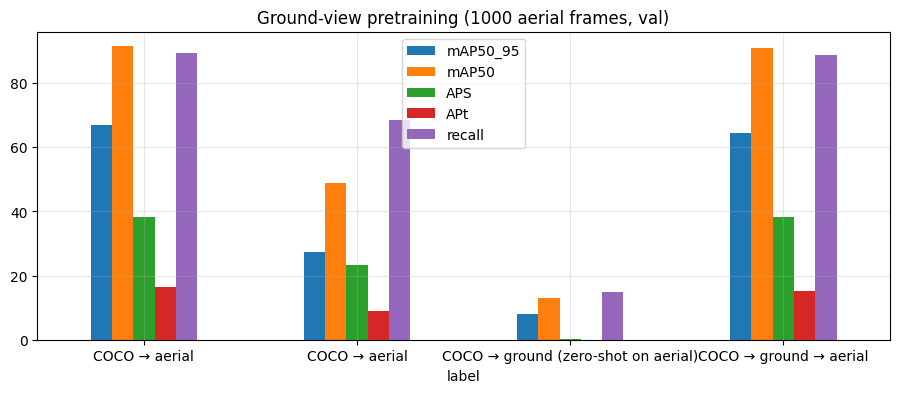

In [8]:
df = ml.results_df()
GR = df[(df.model_version == BEST_MODEL) & (df.eval_split == "val") & (((df.stage == "S5")) | (df.experiment_id == COCO_ROW.experiment_id))]
display(GR[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["seed"]].sort_values(["pretraining", "experiment_id"]))
ml.save_table(GR[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["seed"]], "S5_ground_pretraining")
main = GR[GR.experiment_id.isin([COCO_ROW.experiment_id, GA_ID, G_ID])].copy()
main["label"] = main.experiment_id.map({COCO_ROW.experiment_id: "COCO → aerial", GA_ID: "COCO → ground → aerial", G_ID: "COCO → ground (zero-shot on aerial)"})
main.set_index("label")[["mAP50_95", "mAP50", "APS", "APt", "recall"]].plot.bar(figsize=(11, 4), rot=0)
plt.title("Ground-view pretraining (1000 aerial frames, val)"); plt.grid(alpha=.3); ml.savefig("S5_ground_pretraining.png"); plt.show()

seeds = GR[GR.experiment_id.str.contains("_s1|_s2|_s42") & (GR.tiling == "none") & ~GR.experiment_id.str.contains("groundonly|longer|joint")]
if seeds.seed.nunique() > 1:
    display(seeds.groupby("pretraining")[["mAP50_95", "APS"]].agg(["mean", "std", "count"]))

In [9]:
RUN_JOINT = False
if RUN_JOINT:
    jp, jpack = ml.combine_datasets([(f"aerial_train_{N_SCREEN}", "aerial_1280"), (GROUND, "ground_1280")], f"joint_a{N_SCREEN}_g{ml.N_GROUND}")
    ml.run_experiment(ml.make_spec(BEST_MODEL, jp, BEST_RES, stage="S5", train_pack=jpack, pretraining="COCO", tag="joint",
                                   dataset_size=N_SCREEN, notes="aerial + ground mixed in one training set"))
RUN_STACK_TILING = False
if RUN_STACK_TILING and ml.get_decision("use_tiling", False):
    st = ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", stage="S5", tiling="tile_train", init=f"exp:{G_ID}", pretraining="COCO>MAVREC-ground",
                      epochs=max(3, round(E / 5)), full_res=1280)
    ml.run_experiment(st, eval_modes=["sliced", "sliced+full"])

## Results

In [10]:
ga = df[(df.experiment_id == GA_ID) & (df.eval_split == "val")].iloc[0]
g = ml.component_gain(COCO_ROW, ga)
longer = df[df.experiment_id.str.contains("_longer") & (df.model_version == BEST_MODEL) & (df.eval_split == "val")]
if len(longer):
    gl = ml.component_gain(longer.iloc[0], ga)
    print("vs compute-matched control:", gl)
    # the gain must not be explained by extra epochs alone: COCO->ground->aerial must ALSO pass the
    # component rule against the compute-matched COCO->aerial control
    g["keep"] = g["keep"] and gl["keep"]
    g["vs_compute_matched"] = gl
print(g)
ml.set_decision("use_ground", g["keep"], f"COCO->ground->aerial vs COCO->aerial at {N_SCREEN} frames: {g}")
ml.set_decision("ground_exp", G_ID, "ground-pretrained checkpoint used as init in notebook 08")

vs compute-matched control: {'delta_mAP50_95': -5.52, 'delta_APS': -4.88, 'keep': False}
{'delta_mAP50_95': -2.43, 'delta_APS': -0.24, 'keep': False, 'vs_compute_matched': {'delta_mAP50_95': -5.52, 'delta_APS': -4.88, 'keep': False}}
DECISION use_ground = False
DECISION ground_exp = S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly


'S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly'

In [ ]:
# Optional · Paper check: does ground-view pretraining help Deformable DETR (the paper's model)?
# Exploratory only — sets no decision (use_ground above is about BEST_MODEL). Mirrors the S1 Deformable DETR control:
# 1000 aerial frames, 960 px, COCO init. GPU cost: the control took ~3.8 h, so expect ~7-8 h ground + ~4 h aerial
# with default epochs (training resumes after a disconnect; set DETR_GROUND_EPOCHS = 15 to roughly halve step 1).
RUN_DETR_GROUND = True
DETR, DETR_RES = "deformable_detr", 960
DETR_GROUND_EPOCHS = None  # None = ml.DEFAULT_EPOCHS["deformable_detr"]
if RUN_DETR_GROUND:
    ekw = dict(epochs=DETR_GROUND_EPOCHS) if DETR_GROUND_EPOCHS else {}
    dg = ml.make_spec(DETR, GROUND, DETR_RES, stage="S5", train_pack="ground_1280", pretraining="COCO", tag="groundonly",
                      notes="paper check: Deformable DETR ground-view pretraining; aerial val = zero-shot cross-view", **ekw)
    ml.run_experiment(dg)
    dga = ml.make_spec(DETR, f"aerial_train_{N_SCREEN}", DETR_RES, stage="S5", init=f"exp:{dg['experiment_id']}",
                       pretraining="COCO>MAVREC-ground", notes="paper check: Deformable DETR COCO -> ground -> aerial")
    ml.run_experiment(dga)
    dfd = ml.results_df()
    dctrl = dfd[(dfd.model_version == DETR) & (dfd.dataset_size == N_SCREEN) & (dfd.resolution == DETR_RES) & (dfd.pretraining == "COCO")
                & (dfd.stage == "S1") & (dfd.eval_split == "val") & (dfd.inference_mode == "full")].iloc[0]
    dres = dfd[dfd.experiment_id.isin([dctrl.experiment_id, dg["experiment_id"], dga["experiment_id"]]) & (dfd.eval_split == "val")]
    display(dres[["experiment_id", "pretraining", "mAP50_95", "mAP50", "APS", "APt", "recall", "train_time_h"]])
    ddet = dres[dres.experiment_id == dga["experiment_id"]].iloc[0]
    print("Deformable DETR, COCO->ground->aerial vs COCO->aerial:", ml.component_gain(dctrl, ddet))


Pack 'ground_1280' unpacked to local disk in 17s
[S5_deformable_detr_g2000_r960_full_COCO_s42_groundonly] training deformable_detr | data=ground_train_2000 | res=960 | epochs=30 | batch=2 | init=coco


config.json:   0%|          | 0.00/4.54k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  161MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/545 [00:00<?, ?it/s]

...

epoch 22/30 loss 0.4488 (848s)
epoch 23/30 loss 0.4285 (848s)
epoch 24/30 loss 0.4223 (849s)
epoch 25/30 loss 0.4141 (849s)
epoch 26/30 loss 0.4044 (849s)
epoch 27/30 loss 0.3988 (850s)
epoch 28/30 loss 0.3959 (847s)
epoch 29/30 loss 0.3883 (848s)
epoch 30/30 loss 0.3871 (849s)


Loading weights:   0%|          | 0/545 [00:00<?, ?it/s]

Pack 'aerial_1280' unpacked to local disk in 58s
  predicted 538 images (full) in 77s, 155902 detections
[S5_deformable_detr_g2000_r960_full_COCO_s42_groundonly] val|full|r960: mAP50-95=1.508 AP50=3.099 APS=0.086 APt=0.0 R=10.548 FPS=7.34
[S5_deformable_detr_n1000_r960_full_COCO2MAVRECground_s42] training deformable_detr | data=aerial_train_1000 | res=960 | epochs=30 | batch=2 | init=exp:S5_deformable_detr_g2000_r960_full_COCO_s42_groundonly


Loading weights:   0%|          | 0/545 [00:00<?, ?it/s]

  loaded 585/585 tensors from checkpoint (shape-matched)
epoch 1/30 loss 2.1910 (428s)
epoch 2/30 loss 1.8140 (428s)
epoch 3/30 loss 1.6840 (430s)
epoch 4/30 loss 1.6618 (429s)
epoch 5/30 loss 1.5773 (429s)
epoch 6/30 loss 1.5799 (429s)
epoch 7/30 loss 1.5154 (430s)
epoch 8/30 loss 1.4973 (428s)
epoch 9/30 loss 1.4663 (428s)
epoch 10/30 loss 1.4559 (429s)
epoch 11/30 loss 1.4355 (428s)
epoch 12/30 loss 1.4422 (429s)
epoch 13/30 loss 1.4317 (428s)
epoch 14/30 loss 1.4357 (429s)
epoch 15/30 loss 1.4216 (429s)
epoch 16/30 loss 1.4123 (428s)
epoch 17/30 loss 1.3731 (429s)
epoch 18/30 loss 1.3471 (430s)
epoch 19/30 loss 1.3346 (428s)
